# CLIP + AST + ontology + candidate rules — development 6000

Full candidate-conditioned method. Existing ontology corrections are preserved,
and candidate-specific rules are applied only when the ontology has retained
CLIP Top-1. The three candidate families are represented with `frozenset`, so
membership is independent of Top-3 ordering.

## Setup

In [7]:
from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt
PROJECT_ROOT = Path('C:\\Users\\22313906t\\Desktop\\TAU_project')
CLIP_PATH = PROJECT_ROOT / 'results_CLIP' / 'tau_6000_clip_predictions.csv'
AST_PATH = PROJECT_ROOT / 'results_AST_6000' / 'tau_all_ast_events.csv'
ONTOLOGY_PATH = PROJECT_ROOT / 'results_ONTOLOGY' / 'tau_6000_clip_ast_ontology.csv'
OUTPUT_DIR = PROJECT_ROOT / 'results_ONTOLOGY_CONTEXT_UNIFIED_6000'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTIONS_PATH = OUTPUT_DIR / 'tau_6000_unified_candidate_predictions.csv'
CHANGES_PATH = OUTPUT_DIR / 'tau_6000_unified_candidate_changes.csv'
RULE_SUMMARY_PATH = OUTPUT_DIR / 'tau_6000_unified_candidate_rule_summary.csv'
PER_CLASS_PATH = OUTPUT_DIR / 'tau_6000_unified_candidate_per_class.csv'
SUMMARY_PATH = OUTPUT_DIR / 'tau_6000_unified_candidate_summary.csv'
REPORT_PATH = OUTPUT_DIR / 'tau_6000_unified_candidate_classification_report.csv'
CONFUSION_PATH = OUTPUT_DIR / 'tau_6000_unified_candidate_confusion_matrix.png'
CONFIG_PATH = OUTPUT_DIR / 'tau_6000_unified_candidate_config.json'
TAU_CLASSES = [
    'airport',
    'bus',
    'metro',
    'metro station',
    'park',
    'public square',
    'shopping mall',
    'pedestrian street',
    'street traffic',
    'tram',
]
EXPECTED_TOTAL = 6000
N_PER_CLASS = 600
CLIP_SCORE_COLS = {scene: scene.replace(' ', '_') + '_score' for scene in TAU_CLASSES}


## Candidate sets and thresholds

The rule families are `{bus, metro, tram}`, `{park, pedestrian street,
street traffic}`, and `{metro, metro station, tram}`. Thresholds below are the
fixed development values used by the unified implementation.

In [8]:
TRANSPORT_SET = frozenset(['bus', 'metro', 'tram'])
PARK_SET = frozenset(['park', 'pedestrian street', 'street traffic'])
STATION_SET = frozenset(['metro', 'metro station', 'tram'])
CONTEXT_MIN_SCORE = 0.015
CONTEXT_MIN_PERSISTENCE = 0.25
TRANSPORT_NORMAL_GAP = 0.2
TRANSPORT_STRONG_GAP = 0.45
MIN_ACTIVE_ROAD_CUES = 2
BUS_ANCHOR_EFFECTIVE_MIN = 0.04
ROAD_CUES = {
    'motor_vehicle': {'aliases': ['motor vehicle road'], 'weight': 0.55},
    'revving': {'aliases': ['accelerating revving vroom'], 'weight': 0.5},
    'truck': {'aliases': ['truck'], 'weight': 0.45},
    'engine': {'aliases': ['engine'], 'weight': 0.35},
    'car_passing': {'aliases': ['car passing by', 'car passing'], 'weight': 0.35},
}
RAIL_CUES = {'train': ['train'], 'railroad_car': ['railroad car train wagon', 'railroad car']}
BUS_ANCHOR_EVENTS = ['bus']
PARK_BIRD_MIN_SCORE = 0.1
PARK_BIRD_MIN_PERSISTENCE = 0.5
PARK_SILENCE_MIN_SCORE = 0.03
PARK_SILENCE_MIN_PERSISTENCE = 0.5
PARK_TRAFFIC_BLOCK_SCORE = 0.1
PARK_TRAFFIC_BLOCK_PERSISTENCE = 0.5
PARK_MAX_VISUAL_GAP = 0.25
BIRD_EVENTS = ['bird', 'bird vocalization bird call bird song']
SILENCE_EVENTS = ['silence']
PARK_TRAFFIC_EVENTS = [
    'vehicle',
    'car',
    'motor vehicle road',
    'traffic noise roadway noise',
    'engine',
    'truck',
    'accelerating revving vroom',
    'car passing by',
    'vehicle horn car horn honking',
]
STATION_HUMAN_MIN_SCORE = 0.3
STATION_HUMAN_MIN_PERSISTENCE = 0.75
STATION_SUPPORT_MIN_SCORE = 0.02
STATION_SUPPORT_MIN_PERSISTENCE = 0.25
STATION_NORMAL_GAP = 0.2
STATION_STRONG_GAP = 0.35
HUMAN_EVENTS = ['speech', 'music']
STATION_RAIL_EVENTS = [
    'train',
    'rail transport',
    'railroad car train wagon',
    'railroad car',
    'train wheels squealing',
    'subway metro underground',
]
STATION_ACCESS_EVENTS = ['sliding door', 'door']
print('=' * 80)
print('TAU 6000 DEVELOPMENT')
print('UNIFIED CLIP + AST + ONTOLOGY + CANDIDATE RULES')
print('=' * 80)
print('\nCLIP:')
print(CLIP_PATH)
print('\nAST:')
print(AST_PATH)
print('\nOntology:')
print(ONTOLOGY_PATH)
print('\nOutput:')
print(OUTPUT_DIR)
for path in [CLIP_PATH, AST_PATH, ONTOLOGY_PATH]:
    if not path.exists():
        raise FileNotFoundError(f'Cannot find:\n{path}')


TAU 6000 DEVELOPMENT
UNIFIED CLIP + AST + ONTOLOGY + CANDIDATE RULES

CLIP:
C:\Users\22313906t\Desktop\TAU_project\results_CLIP\tau_6000_clip_predictions.csv

AST:
C:\Users\22313906t\Desktop\TAU_project\results_AST_6000\tau_all_ast_events.csv

Ontology:
C:\Users\22313906t\Desktop\TAU_project\results_ONTOLOGY\tau_6000_clip_ast_ontology.csv

Output:
C:\Users\22313906t\Desktop\TAU_project\results_ONTOLOGY_CONTEXT_UNIFIED_6000


## Load data and build AST lookup

In [9]:
def norm_event(x):
    x = str(x).lower()
    x = re.sub('[^a-z0-9]+', ' ', x)
    x = re.sub('\\s+', ' ', x)
    return x.strip()


def norm_scene(x):
    x = str(x).strip().lower()
    aliases = {
        'street_pedestrian': 'pedestrian street',
        'street pedestrian': 'pedestrian street',
        'metro_station': 'metro station',
        'public_square': 'public square',
        'shopping_mall': 'shopping mall',
        'street_traffic': 'street traffic',
    }
    return aliases.get(x, x)


def safe_float(value, default=0.0):
    try:
        value = float(value)
        if np.isfinite(value):
            return value
    except Exception:
        pass
    return default


clip_df = pd.read_csv(CLIP_PATH)
clip_df['clip_id'] = clip_df['clip_id'].astype(str)
clip_df['ground_truth'] = clip_df['ground_truth'].apply(norm_scene)
for col in ['clip_top1', 'clip_top2', 'clip_top3']:
    clip_df[col] = clip_df[col].apply(norm_scene)
clip_df = clip_df.drop_duplicates(subset=['clip_id'], keep='last').reset_index(drop=True)
for scene, col in CLIP_SCORE_COLS.items():
    if col not in clip_df.columns:
        raise ValueError(f'Missing CLIP score column: {col}')
ontology_df = pd.read_csv(ONTOLOGY_PATH)
ontology_df['clip_id'] = ontology_df['clip_id'].astype(str)
if 'ast_v1_prediction' not in ontology_df.columns:
    possible = ['ontology_prediction', 'ast_corrected_prediction', 'prediction']
    found = None
    for col in possible:
        if col in ontology_df.columns:
            found = col
            break
    if found is None:
        raise ValueError('Could not find basic ontology prediction column.')
    ontology_df['ast_v1_prediction'] = ontology_df[found]
ontology_df['ast_v1_prediction'] = ontology_df['ast_v1_prediction'].apply(norm_scene)
ontology_df = ontology_df[
    ['clip_id', 'ast_v1_prediction']].drop_duplicates(subset=['clip_id'],
    keep='last',
)
df = clip_df.merge(ontology_df, on='clip_id', how='left', validate='one_to_one')
if df['ast_v1_prediction'].isna().any():
    missing_ids = df.loc[df['ast_v1_prediction'].isna(), 'clip_id'].tolist()
    print(missing_ids[:20])
    raise RuntimeError('Some CLIP clips have no basic ontology prediction.')
print('\n' + '=' * 80)
print('DEVELOPMENT SET CHECK')
print('=' * 80)
print('Rows:', len(df))
print('Unique IDs:', df['clip_id'].nunique())
class_counts = df['ground_truth'].value_counts().reindex(TAU_CLASSES, fill_value=0)
print('\nClass distribution:')
print(class_counts)
if len(df) != EXPECTED_TOTAL:
    raise ValueError(f'Expected {EXPECTED_TOTAL} rows, found {len(df)}.')
if df['clip_id'].nunique() != EXPECTED_TOTAL:
    raise ValueError('Expected 6000 unique IDs.')
if not (class_counts == N_PER_CLASS).all():
    raise ValueError('Development set is not balanced at 600 clips/class.')
ast_df = pd.read_csv(AST_PATH)
ast_df['clip_id'] = ast_df['clip_id'].astype(str)
EVENT_COL = None
for col in ['label', 'event', 'event_label', 'audio_event', 'class_name']:
    if col in ast_df.columns:
        EVENT_COL = col
        break
if EVENT_COL is None:
    raise ValueError(f'Could not identify AST event column.\n{list(ast_df.columns)}')
SCORE_COL = None
for col in ['max_score', 'score', 'mean_score']:
    if col in ast_df.columns:
        SCORE_COL = col
        break
if SCORE_COL is None:
    raise ValueError('Could not identify AST score column.')
if 'persistence' not in ast_df.columns:
    if 'count' in ast_df.columns and 'num_chunks' in ast_df.columns:
        ast_df[
            'persistence'] = pd.to_numeric(ast_df['count'],
            errors='coerce') / pd.to_numeric(ast_df['num_chunks'],
            errors='coerce').replace(0,
            np.nan,
        )
    else:
        raise ValueError('AST file requires persistence or count + num_chunks.')
ast_df['event_norm'] = ast_df[EVENT_COL].apply(norm_event)
ast_df['event_score'] = pd.to_numeric(ast_df[SCORE_COL], errors='coerce').fillna(0.0)
ast_df['persistence'] = pd.to_numeric(ast_df['persistence'], errors='coerce').fillna(0.0)
development_ids = set(df['clip_id'])
ast_df = ast_df[ast_df['clip_id'].isin(development_ids)].copy()
matched_ast_ids = set(ast_df['clip_id'])
missing_ast = development_ids - matched_ast_ids
print('\nAST matched clips:')
print(len(matched_ast_ids))
print('Missing AST clips:', len(missing_ast))
if missing_ast:
    print(sorted(missing_ast)[:20])
    raise RuntimeError('AST coverage is incomplete.')
ast_lookup = {}
for (clip_id, event_name), group in ast_df.groupby(['clip_id', 'event_norm']):
    best_index = group['event_score'].idxmax()
    best_row = group.loc[best_index]
    ast_lookup[
        clip_id,
        event_name] = {'score': safe_float(best_row['event_score']),
        'persistence': safe_float(best_row['persistence']),
    }



DEVELOPMENT SET CHECK
Rows: 6000
Unique IDs: 6000

Class distribution:
ground_truth
airport              600
bus                  600
metro                600
metro station        600
park                 600
public square        600
shopping mall        600
pedestrian street    600
street traffic       600
tram                 600
Name: count, dtype: int64

AST matched clips:
6000
Missing AST clips: 0


## Candidate evidence helpers

In [10]:
def get_event(clip_id, aliases):
    best_score = 0.0
    best_persistence = 0.0
    best_event = None
    for alias in aliases:
        alias = norm_event(alias)
        item = ast_lookup.get((clip_id, alias))
        if item is None:
            continue
        if item['score'] > best_score:
            best_score = item['score']
            best_persistence = item['persistence']
            best_event = alias
    return {
        'event': best_event,
        'score': best_score,
        'persistence': best_persistence,
        'effective': best_score * best_persistence,
    }


def event_active(event_info, min_score, min_persistence):
    return event_info['score'] >= min_score and event_info['persistence'] >= min_persistence


def any_event_active(clip_id, aliases, min_score, min_persistence):
    event_info = get_event(clip_id, aliases)
    return (event_active(event_info, min_score, min_persistence), event_info)


def clip_score(row, scene):
    col = CLIP_SCORE_COLS[scene]
    return safe_float(row[col])


def get_road_context(clip_id):
    active_cues = []
    weighted_score = 0.0
    details = []
    for cue_name, config in ROAD_CUES.items():
        info = get_event(clip_id, config['aliases'])
        active = event_active(info, CONTEXT_MIN_SCORE, CONTEXT_MIN_PERSISTENCE)
        contribution = 0.0
        if active:
            active_cues.append(cue_name)
            contribution = info['score'] * info['persistence'] * config['weight']
            weighted_score += contribution
        details.append({'cue': cue_name, 'score': info['score'], 'persistence': info['persistence'], 'active': active, 'contribution': contribution})
    return {
        'active_count': len(active_cues),
        'active_cues': active_cues,
        'weighted_score': weighted_score,
        'details': details,
    }


def get_bus_anchor(clip_id):
    info = get_event(clip_id, BUS_ANCHOR_EVENTS)
    strong = info['effective'] >= BUS_ANCHOR_EFFECTIVE_MIN
    return (strong, info)


def get_transport_rail_context(clip_id):
    train_info = get_event(clip_id, RAIL_CUES['train'])
    railroad_info = get_event(clip_id, RAIL_CUES['railroad_car'])
    train_active = event_active(train_info, CONTEXT_MIN_SCORE, CONTEXT_MIN_PERSISTENCE)
    railroad_active = event_active(railroad_info, CONTEXT_MIN_SCORE, CONTEXT_MIN_PERSISTENCE)
    count = int(train_active) + int(railroad_active)
    return {
        'train_active': train_active,
        'railroad_active': railroad_active,
        'count': count,
        'train_score': train_info['score'],
        'train_persistence': train_info['persistence'],
        'railroad_score': railroad_info['score'],
        'railroad_persistence': railroad_info['persistence'],
    }


def get_park_context(clip_id):
    bird_info = get_event(clip_id, BIRD_EVENTS)
    silence_info = get_event(clip_id, SILENCE_EVENTS)
    bird_active = event_active(bird_info, PARK_BIRD_MIN_SCORE, PARK_BIRD_MIN_PERSISTENCE)
    silence_active = event_active(silence_info, PARK_SILENCE_MIN_SCORE, PARK_SILENCE_MIN_PERSISTENCE)
    strongest_traffic = get_event(clip_id, PARK_TRAFFIC_EVENTS)
    traffic_block = event_active(
        strongest_traffic,
        PARK_TRAFFIC_BLOCK_SCORE,
        PARK_TRAFFIC_BLOCK_PERSISTENCE,
    )
    return {
        'bird_active': bird_active,
        'bird_score': bird_info['score'],
        'bird_persistence': bird_info['persistence'],
        'silence_active': silence_active,
        'silence_score': silence_info['score'],
        'silence_persistence': silence_info['persistence'],
        'traffic_block': traffic_block,
        'traffic_event': strongest_traffic['event'],
        'traffic_score': strongest_traffic['score'],
        'traffic_persistence': strongest_traffic['persistence'],
    }


def get_station_context(clip_id):
    human_info = get_event(clip_id, HUMAN_EVENTS)
    human_active = event_active(human_info, STATION_HUMAN_MIN_SCORE, STATION_HUMAN_MIN_PERSISTENCE)
    rail_info = get_event(clip_id, STATION_RAIL_EVENTS)
    rail_active = event_active(rail_info, STATION_SUPPORT_MIN_SCORE, STATION_SUPPORT_MIN_PERSISTENCE)
    access_info = get_event(clip_id, STATION_ACCESS_EVENTS)
    access_active = event_active(access_info, STATION_SUPPORT_MIN_SCORE, STATION_SUPPORT_MIN_PERSISTENCE)
    return {
        'human_active': human_active,
        'human_event': human_info['event'],
        'human_score': human_info['score'],
        'human_persistence': human_info['persistence'],
        'rail_active': rail_active,
        'rail_event': rail_info['event'],
        'rail_score': rail_info['score'],
        'rail_persistence': rail_info['persistence'],
        'access_active': access_active,
        'access_event': access_info['event'],
        'access_score': access_info['score'],
        'access_persistence': access_info['persistence'],
    }


## Apply candidate-conditioned rules

The final prediction starts from the ontology result. If the ontology
already corrected CLIP, that decision is preserved. Otherwise, only the matching
candidate-family rule is evaluated.

In [11]:
output_rows = []
for index, row in df.iterrows():
    clip_id = str(row['clip_id'])
    ground_truth = norm_scene(row['ground_truth'])
    clip_top1 = norm_scene(row['clip_top1'])
    clip_top2 = norm_scene(row['clip_top2'])
    clip_top3 = norm_scene(row['clip_top3'])
    ontology_prediction = norm_scene(row['ast_v1_prediction'])
    candidate_set = frozenset([clip_top1, clip_top2, clip_top3])
    final_prediction = ontology_prediction
    rule_name = 'NONE'
    rule_reason = 'No candidate-conditioned intervention'
    rule_changed = False
    visual_gap = np.nan
    road_active_count = 0
    road_context_score = 0.0
    road_active_cues = ''
    bus_anchor_score = 0.0
    bus_anchor_persistence = 0.0
    bus_anchor_effective = 0.0
    bus_anchor_strong = False
    rail_count = 0
    train_active = False
    railroad_active = False
    bird_active = False
    bird_score = 0.0
    bird_persistence = 0.0
    silence_active = False
    silence_score = 0.0
    silence_persistence = 0.0
    traffic_block = False
    traffic_event = ''
    traffic_score = 0.0
    traffic_persistence = 0.0
    station_human_active = False
    station_human_event = ''
    station_human_score = 0.0
    station_human_persistence = 0.0
    station_rail_active = False
    station_rail_event = ''
    station_rail_score = 0.0
    station_rail_persistence = 0.0
    station_access_active = False
    station_access_event = ''
    station_access_score = 0.0
    station_access_persistence = 0.0
    if ontology_prediction != clip_top1:
        rule_name = 'PRESERVE_ONTOLOGY'
        rule_reason = 'Basic ontology correction preserved'
    elif candidate_set == TRANSPORT_SET:
        road = get_road_context(clip_id)
        road_active_count = road['active_count']
        road_context_score = road['weighted_score']
        road_active_cues = ','.join(road['active_cues'])
        bus_anchor_strong, bus_anchor = get_bus_anchor(clip_id)
        bus_anchor_score = bus_anchor['score']
        bus_anchor_persistence = bus_anchor['persistence']
        bus_anchor_effective = bus_anchor['effective']
        rail = get_transport_rail_context(clip_id)
        rail_count = rail['count']
        train_active = rail['train_active']
        railroad_active = rail['railroad_active']
        if clip_top1 in ['metro', 'tram']:
            bus_gap = clip_score(row, clip_top1) - clip_score(row, 'bus')
            bus_gap = max(0.0, bus_gap)
            visual_gap = bus_gap
            allowed_gap = TRANSPORT_STRONG_GAP if bus_anchor_strong else TRANSPORT_NORMAL_GAP
            if road_active_count >= MIN_ACTIVE_ROAD_CUES:
                if bus_gap <= allowed_gap:
                    final_prediction = 'bus'
                    rule_name = 'BMT_ROAD_TO_BUS'
                    rule_reason = f'{road_active_count} persistent road cues support Bus'
                    rule_changed = final_prediction != ontology_prediction
        elif clip_top1 == 'bus':
            if rail_count >= 1:
                metro_score = clip_score(row, 'metro')
                tram_score = clip_score(row, 'tram')
                if metro_score >= tram_score:
                    rail_candidate = 'metro'
                else:
                    rail_candidate = 'tram'
                rail_gap = clip_score(row, 'bus') - clip_score(row, rail_candidate)
                rail_gap = max(0.0, rail_gap)
                visual_gap = rail_gap
                if rail_count >= 2:
                    allowed_gap = TRANSPORT_STRONG_GAP
                else:
                    allowed_gap = TRANSPORT_NORMAL_GAP
                if rail_gap <= allowed_gap:
                    final_prediction = rail_candidate
                    rule_name = 'BMT_RAIL_CHALLENGE_BUS'
                    rule_reason = f'{rail_count} rail cue(s) challenge Bus; CLIP selects rail sibling'
                    rule_changed = final_prediction != ontology_prediction
    elif candidate_set == PARK_SET:
        park_context = get_park_context(clip_id)
        bird_active = park_context['bird_active']
        bird_score = park_context['bird_score']
        bird_persistence = park_context['bird_persistence']
        silence_active = park_context['silence_active']
        silence_score = park_context['silence_score']
        silence_persistence = park_context['silence_persistence']
        traffic_block = park_context['traffic_block']
        traffic_event = park_context['traffic_event'] or ''
        traffic_score = park_context['traffic_score']
        traffic_persistence = park_context['traffic_persistence']
        if clip_top1 != 'park':
            park_gap = clip_score(row, clip_top1) - clip_score(row, 'park')
            park_gap = max(0.0, park_gap)
            visual_gap = park_gap
            if bird_active and silence_active and (not traffic_block) and (park_gap <= PARK_MAX_VISUAL_GAP):
                final_prediction = 'park'
                rule_name = 'PARK_BIRD_QUIET'
                rule_reason = 'Persistent Bird + quiet context with no strong traffic evidence'
                rule_changed = final_prediction != ontology_prediction
    elif candidate_set == STATION_SET:
        station_context = get_station_context(clip_id)
        station_human_active = station_context['human_active']
        station_human_event = station_context['human_event'] or ''
        station_human_score = station_context['human_score']
        station_human_persistence = station_context['human_persistence']
        station_rail_active = station_context['rail_active']
        station_rail_event = station_context['rail_event'] or ''
        station_rail_score = station_context['rail_score']
        station_rail_persistence = station_context['rail_persistence']
        station_access_active = station_context['access_active']
        station_access_event = station_context['access_event'] or ''
        station_access_score = station_context['access_score']
        station_access_persistence = station_context['access_persistence']
        if clip_top1 != 'metro station':
            station_gap = clip_score(row, clip_top1) - clip_score(row, 'metro station')
            station_gap = max(0.0, station_gap)
            visual_gap = station_gap
            strong_station_context = station_human_active and station_rail_active and station_access_active
            normal_station_context = station_human_active and (station_rail_active or station_access_active)
            if strong_station_context:
                allowed_gap = STATION_STRONG_GAP
            else:
                allowed_gap = STATION_NORMAL_GAP
            if normal_station_context and station_gap <= allowed_gap:
                final_prediction = 'metro station'
                if strong_station_context:
                    rule_name = 'STATION_HUMAN_RAIL_ACCESS'
                    rule_reason = 'Strong human + rail + access station context'
                elif station_rail_active:
                    rule_name = 'STATION_HUMAN_RAIL'
                    rule_reason = 'Persistent human context supported by rail evidence'
                else:
                    rule_name = 'STATION_HUMAN_ACCESS'
                    rule_reason = 'Persistent human context supported by access evidence'
                rule_changed = final_prediction != ontology_prediction
    output = {
        'clip_id': clip_id,
        'ground_truth': ground_truth,
        'clip_top1': clip_top1,
        'clip_top2': clip_top2,
        'clip_top3': clip_top3,
        'ast_v1_prediction': ontology_prediction,
        'context_v2_prediction': final_prediction,
        'candidate_rule': rule_name,
        'rule_reason': rule_reason,
        'rule_changed': rule_changed,
        'candidate_set': ' | '.join(sorted(candidate_set)),
        'visual_gap': visual_gap,
        'road_active_count': road_active_count,
        'road_active_cues': road_active_cues,
        'road_context_score': road_context_score,
        'bus_anchor_score': bus_anchor_score,
        'bus_anchor_persistence': bus_anchor_persistence,
        'bus_anchor_effective': bus_anchor_effective,
        'bus_anchor_strong': bus_anchor_strong,
        'rail_cue_count': rail_count,
        'train_active': train_active,
        'railroad_active': railroad_active,
        'bird_active': bird_active,
        'bird_score': bird_score,
        'bird_persistence': bird_persistence,
        'silence_active': silence_active,
        'silence_score': silence_score,
        'silence_persistence': silence_persistence,
        'traffic_block': traffic_block,
        'traffic_event': traffic_event,
        'traffic_score': traffic_score,
        'traffic_persistence': traffic_persistence,
        'station_human_active': station_human_active,
        'station_human_event': station_human_event,
        'station_human_score': station_human_score,
        'station_human_persistence': station_human_persistence,
        'station_rail_active': station_rail_active,
        'station_rail_event': station_rail_event,
        'station_rail_score': station_rail_score,
        'station_rail_persistence': station_rail_persistence,
        'station_access_active': station_access_active,
        'station_access_event': station_access_event,
        'station_access_score': station_access_score,
        'station_access_persistence': station_access_persistence,
    }
    output_rows.append(output)
    if (index + 1) % 500 == 0:
        print(f'Processed {index + 1} / {len(df)}')


Processed 500 / 6000
Processed 1000 / 6000
Processed 1500 / 6000
Processed 2000 / 6000
Processed 2500 / 6000
Processed 3000 / 6000
Processed 3500 / 6000
Processed 4000 / 6000
Processed 4500 / 6000
Processed 5000 / 6000
Processed 5500 / 6000
Processed 6000 / 6000


## Evaluation and outputs


DEVELOPMENT RESULTS
CLIP accuracy:                    78.9333%
Basic ontology accuracy:          79.7333%
Final candidate-rule accuracy:    81.1167%

Gain vs CLIP:                    +2.1833 points
Gain vs ontology:                 +1.3833 points

CLIP Macro-F1:                  0.787749
Ontology Macro-F1:               0.795959
Final Macro-F1:                  0.808488

CANDIDATE RULES — CHANGES RELATIVE TO BASIC ONTOLOGY
Predictions changed: 175
Wrong -> Correct: 118
Correct -> Wrong: 35
Wrong -> Wrong: 22
Correct -> Correct: 0
Net gain: 83
Candidate-rule correction precision: 67.43%

FULL FINAL SYSTEM — CHANGES RELATIVE TO CLIP
Predictions different from CLIP: 233
Wrong -> Correct: 169
Correct -> Wrong: 38
Wrong -> Wrong: 26
Net gain: 131

RULE SUMMARY
           candidate_rule change_vs_ontology  count
   BMT_RAIL_CHALLENGE_BUS     Correct->Wrong     13
   BMT_RAIL_CHALLENGE_BUS     Wrong->Correct      6
   BMT_RAIL_CHALLENGE_BUS       Wrong->Wrong      5
          BMT_ROAD_TO_BUS

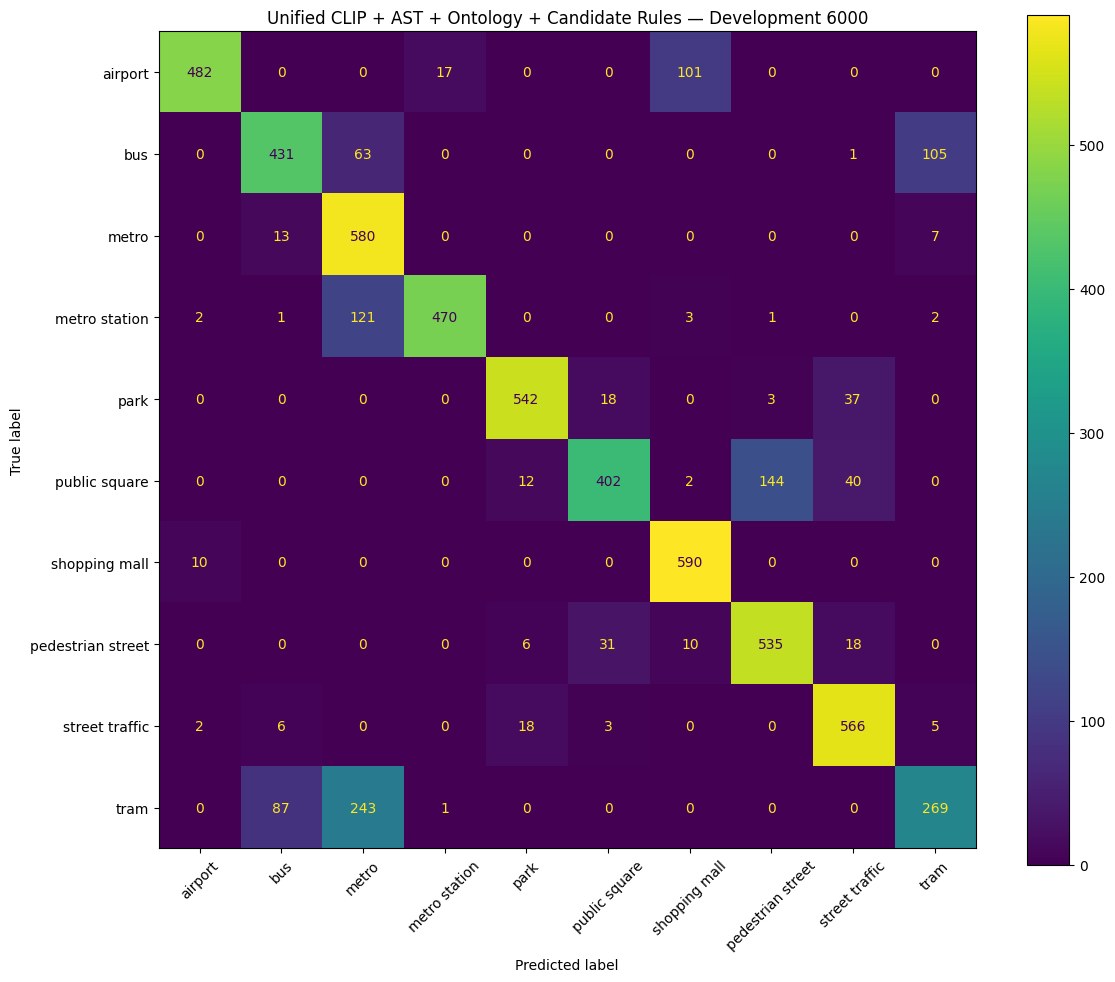


CANDIDATE-RULE CHANGES
                         clip_id  ground_truth      clip_top1 ast_v1_prediction context_v2_prediction change_vs_ontology            candidate_rule  visual_gap                                                     rule_reason
             bus-lyon-1124-41154           bus          metro             metro                   bus     Wrong->Correct           BMT_ROAD_TO_BUS    0.161555                              3 persistent road cues support Bus
          tram-lisbon-1200-45720          tram           tram              tram                   bus     Correct->Wrong           BMT_ROAD_TO_BUS    0.177405                              2 persistent road cues support Bus
            bus-barcelona-17-703           bus           tram              tram                   bus     Wrong->Correct           BMT_ROAD_TO_BUS    0.210386                              3 persistent road cues support Bus
            bus-milan-1083-40287           bus           tram              tram     

In [12]:
result_df = pd.DataFrame(output_rows)
result_df['clip_correct'] = result_df['clip_top1'] == result_df['ground_truth']
result_df['ontology_correct'] = result_df['ast_v1_prediction'] == result_df['ground_truth']
result_df['final_correct'] = result_df['context_v2_prediction'] == result_df['ground_truth']


def change_vs_ontology(row):
    before_prediction = row['ast_v1_prediction']
    after_prediction = row['context_v2_prediction']
    if before_prediction == after_prediction:
        return 'Unchanged'
    before_correct = bool(row['ontology_correct'])
    after_correct = bool(row['final_correct'])
    if not before_correct and after_correct:
        return 'Wrong->Correct'
    if before_correct and (not after_correct):
        return 'Correct->Wrong'
    if not before_correct and (not after_correct):
        return 'Wrong->Wrong'
    return 'Correct->Correct'


result_df['change_vs_ontology'] = result_df.apply(change_vs_ontology, axis=1)


def change_vs_clip(row):
    before_prediction = row['clip_top1']
    after_prediction = row['context_v2_prediction']
    if before_prediction == after_prediction:
        return 'Unchanged'
    before_correct = bool(row['clip_correct'])
    after_correct = bool(row['final_correct'])
    if not before_correct and after_correct:
        return 'Wrong->Correct'
    if before_correct and (not after_correct):
        return 'Correct->Wrong'
    if not before_correct and (not after_correct):
        return 'Wrong->Wrong'
    return 'Correct->Correct'


result_df['change_vs_clip'] = result_df.apply(change_vs_clip, axis=1)
clip_accuracy = accuracy_score(result_df['ground_truth'], result_df['clip_top1'])
ontology_accuracy = accuracy_score(result_df['ground_truth'], result_df['ast_v1_prediction'])
final_accuracy = accuracy_score(result_df['ground_truth'], result_df['context_v2_prediction'])
clip_macro_f1 = f1_score(
    result_df['ground_truth'],
    result_df['clip_top1'],
    labels=TAU_CLASSES,
    average='macro',
    zero_division=0,
)
ontology_macro_f1 = f1_score(
    result_df['ground_truth'],
    result_df['ast_v1_prediction'],
    labels=TAU_CLASSES,
    average='macro',
    zero_division=0,
)
final_macro_f1 = f1_score(
    result_df['ground_truth'],
    result_df['context_v2_prediction'],
    labels=TAU_CLASSES,
    average='macro',
    zero_division=0,
)
candidate_changes_df = result_df[result_df['ast_v1_prediction'] != result_df['context_v2_prediction']].copy()
candidate_wrong_to_correct = int((candidate_changes_df['change_vs_ontology'] == 'Wrong->Correct').sum())
candidate_correct_to_wrong = int((candidate_changes_df['change_vs_ontology'] == 'Correct->Wrong').sum())
candidate_wrong_to_wrong = int((candidate_changes_df['change_vs_ontology'] == 'Wrong->Wrong').sum())
candidate_correct_to_correct = int((candidate_changes_df['change_vs_ontology'] == 'Correct->Correct').sum())
candidate_net = candidate_wrong_to_correct - candidate_correct_to_wrong
final_changes_vs_clip = result_df[result_df['clip_top1'] != result_df['context_v2_prediction']].copy()
clip_wrong_to_correct = int((final_changes_vs_clip['change_vs_clip'] == 'Wrong->Correct').sum())
clip_correct_to_wrong = int((final_changes_vs_clip['change_vs_clip'] == 'Correct->Wrong').sum())
clip_wrong_to_wrong = int((final_changes_vs_clip['change_vs_clip'] == 'Wrong->Wrong').sum())
clip_net = clip_wrong_to_correct - clip_correct_to_wrong
print('\n' + '=' * 80)
print('DEVELOPMENT RESULTS')
print('=' * 80)
print(f'CLIP accuracy:                    {clip_accuracy * 100:.4f}%')
print(f'Basic ontology accuracy:          {ontology_accuracy * 100:.4f}%')
print(f'Final candidate-rule accuracy:    {final_accuracy * 100:.4f}%')
print(f'\nGain vs CLIP:                    {(final_accuracy - clip_accuracy) * 100:+.4f} points')
print(f'Gain vs ontology:                 {(final_accuracy - ontology_accuracy) * 100:+.4f} points')
print(f'\nCLIP Macro-F1:                  {clip_macro_f1:.6f}')
print(f'Ontology Macro-F1:               {ontology_macro_f1:.6f}')
print(f'Final Macro-F1:                  {final_macro_f1:.6f}')
print('\n' + '=' * 80)
print('CANDIDATE RULES — CHANGES RELATIVE TO BASIC ONTOLOGY')
print('=' * 80)
print('Predictions changed:', len(candidate_changes_df))
print('Wrong -> Correct:', candidate_wrong_to_correct)
print('Correct -> Wrong:', candidate_correct_to_wrong)
print('Wrong -> Wrong:', candidate_wrong_to_wrong)
print('Correct -> Correct:', candidate_correct_to_correct)
print('Net gain:', candidate_net)
if len(candidate_changes_df) > 0:
    precision = 100.0 * candidate_wrong_to_correct / len(candidate_changes_df)
else:
    precision = 0.0
print(f'Candidate-rule correction precision: {precision:.2f}%')
print('\n' + '=' * 80)
print('FULL FINAL SYSTEM — CHANGES RELATIVE TO CLIP')
print('=' * 80)
print('Predictions different from CLIP:', len(final_changes_vs_clip))
print('Wrong -> Correct:', clip_wrong_to_correct)
print('Correct -> Wrong:', clip_correct_to_wrong)
print('Wrong -> Wrong:', clip_wrong_to_wrong)
print('Net gain:', clip_net)
rule_summary = result_df[result_df['rule_changed']].groupby(['candidate_rule', 'change_vs_ontology']).size().reset_index(name='count')
print('\n' + '=' * 80)
print('RULE SUMMARY')
print('=' * 80)
if len(rule_summary) == 0:
    print('No candidate rules changed predictions.')
else:
    print(rule_summary.to_string(index=False))
per_class_rows = []
for scene in TAU_CLASSES:
    temp = result_df[result_df['ground_truth'] == scene].copy()
    clip_acc = (temp['clip_top1'] == scene).mean()
    ontology_acc = (temp['ast_v1_prediction'] == scene).mean()
    final_acc = (temp['context_v2_prediction'] == scene).mean()
    candidate_changed = temp[temp['ast_v1_prediction'] != temp['context_v2_prediction']]
    wc = int((candidate_changed['change_vs_ontology'] == 'Wrong->Correct').sum())
    cw = int((candidate_changed['change_vs_ontology'] == 'Correct->Wrong').sum())
    ww = int((candidate_changed['change_vs_ontology'] == 'Wrong->Wrong').sum())
    per_class_rows.append({'class': scene, 'number_of_clips': len(temp), 'clip_accuracy_percent': clip_acc * 100, 'ontology_accuracy_percent': ontology_acc * 100, 'final_accuracy_percent': final_acc * 100, 'gain_vs_clip_points': (final_acc - clip_acc) * 100, 'gain_vs_ontology_points': (final_acc - ontology_acc) * 100, 'candidate_rule_changes': len(candidate_changed), 'wrong_to_correct': wc, 'correct_to_wrong': cw, 'wrong_to_wrong': ww, 'net_gain': wc - cw})
per_class_df = pd.DataFrame(per_class_rows)
print('\n' + '=' * 80)
print('PER-CLASS RESULTS')
print('=' * 80)
print(per_class_df.round(3).to_string(index=False))
report = classification_report(
    result_df['ground_truth'],
    result_df['context_v2_prediction'],
    labels=TAU_CLASSES,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).T
cm = confusion_matrix(result_df['ground_truth'], result_df['context_v2_prediction'], labels=TAU_CLASSES)
fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=TAU_CLASSES)
disp.plot(ax=ax, xticks_rotation=45, values_format='d')
plt.title('Unified CLIP + AST + Ontology + Candidate Rules — Development 6000')
plt.tight_layout()
plt.savefig(CONFUSION_PATH, dpi=300, bbox_inches='tight')
plt.show()
summary_df = pd.DataFrame([{'experiment': 'development_6000_unified', 'number_of_clips': len(result_df), 'clip_accuracy_percent': clip_accuracy * 100, 'clip_macro_f1': clip_macro_f1, 'ontology_accuracy_percent': ontology_accuracy * 100, 'ontology_macro_f1': ontology_macro_f1, 'final_accuracy_percent': final_accuracy * 100, 'final_macro_f1': final_macro_f1, 'final_gain_vs_clip_points': (final_accuracy - clip_accuracy) * 100, 'candidate_gain_vs_ontology_points': (final_accuracy - ontology_accuracy) * 100, 'candidate_changes': len(candidate_changes_df), 'candidate_wrong_to_correct': candidate_wrong_to_correct, 'candidate_correct_to_wrong': candidate_correct_to_wrong, 'candidate_wrong_to_wrong': candidate_wrong_to_wrong, 'candidate_net_gain': candidate_net, 'candidate_correction_precision_percent': precision, 'full_wrong_to_correct_vs_clip': clip_wrong_to_correct, 'full_correct_to_wrong_vs_clip': clip_correct_to_wrong, 'full_wrong_to_wrong_vs_clip': clip_wrong_to_wrong, 'full_net_gain_vs_clip': clip_net}])
config = {
    'experiment': 'development_6000_unified',
    'tuning_in_this_script': False,
    'preserve_basic_ontology_corrections': True,
    'candidate_scope': 'exact CLIP Top-3 sets',
    'transport_set': ['bus', 'metro', 'tram'],
    'transport_context_min_score': CONTEXT_MIN_SCORE,
    'transport_min_persistence': CONTEXT_MIN_PERSISTENCE,
    'transport_min_active_road_cues': MIN_ACTIVE_ROAD_CUES,
    'transport_normal_visual_gap': TRANSPORT_NORMAL_GAP,
    'transport_strong_visual_gap': TRANSPORT_STRONG_GAP,
    'bus_anchor_effective_min': BUS_ANCHOR_EFFECTIVE_MIN,
    'park_set': ['park', 'pedestrian street', 'street traffic'],
    'park_bird_min_score': PARK_BIRD_MIN_SCORE,
    'park_bird_min_persistence': PARK_BIRD_MIN_PERSISTENCE,
    'park_silence_min_score': PARK_SILENCE_MIN_SCORE,
    'park_silence_min_persistence': PARK_SILENCE_MIN_PERSISTENCE,
    'park_traffic_block_score': PARK_TRAFFIC_BLOCK_SCORE,
    'park_traffic_block_persistence': PARK_TRAFFIC_BLOCK_PERSISTENCE,
    'park_max_visual_gap': PARK_MAX_VISUAL_GAP,
    'station_set': ['metro', 'metro station', 'tram'],
    'station_human_min_score': STATION_HUMAN_MIN_SCORE,
    'station_human_min_persistence': STATION_HUMAN_MIN_PERSISTENCE,
    'station_support_min_score': STATION_SUPPORT_MIN_SCORE,
    'station_support_min_persistence': STATION_SUPPORT_MIN_PERSISTENCE,
    'station_normal_visual_gap': STATION_NORMAL_GAP,
    'station_strong_visual_gap': STATION_STRONG_GAP,
}
result_df.to_csv(PREDICTIONS_PATH, index=False)
candidate_changes_df.to_csv(CHANGES_PATH, index=False)
rule_summary.to_csv(RULE_SUMMARY_PATH, index=False)
per_class_df.to_csv(PER_CLASS_PATH, index=False)
summary_df.to_csv(SUMMARY_PATH, index=False)
report_df.to_csv(REPORT_PATH)
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2)
print('\n' + '=' * 80)
print('CANDIDATE-RULE CHANGES')
print('=' * 80)
if len(candidate_changes_df) == 0:
    print('No candidate-conditioned predictions changed.')
else:
    show_columns = [
        'clip_id',
        'ground_truth',
        'clip_top1',
        'ast_v1_prediction',
        'context_v2_prediction',
        'change_vs_ontology',
        'candidate_rule',
        'visual_gap',
        'rule_reason',
    ]
    print(candidate_changes_df[show_columns].to_string(index=False))
harmful_df = candidate_changes_df[candidate_changes_df['change_vs_ontology'] == 'Correct->Wrong']
print('\n' + '=' * 80)
print('CANDIDATE RULE CORRECT -> WRONG CASES')
print('=' * 80)
if len(harmful_df) == 0:
    print('None.')
else:
    print(harmful_df[['clip_id', 'ground_truth', 'ast_v1_prediction', 'context_v2_prediction', 'candidate_rule', 'visual_gap', 'rule_reason']].to_string(index=False))
beneficial_df = candidate_changes_df[candidate_changes_df['change_vs_ontology'] == 'Wrong->Correct']
print('\n' + '=' * 80)
print('CANDIDATE RULE WRONG -> CORRECT CASES')
print('=' * 80)
if len(beneficial_df) == 0:
    print('None.')
else:
    print(beneficial_df[['clip_id', 'ground_truth', 'ast_v1_prediction', 'context_v2_prediction', 'candidate_rule', 'visual_gap', 'rule_reason']].to_string(index=False))
print('\n' + '=' * 80)
print('FILES SAVED')
print('=' * 80)
print('\nFinal predictions:')
print(PREDICTIONS_PATH)
print('\nCandidate-rule changes:')
print(CHANGES_PATH)
print('\nRule summary:')
print(RULE_SUMMARY_PATH)
print('\nPer-class results:')
print(PER_CLASS_PATH)
print('\nSummary:')
print(SUMMARY_PATH)
print('\nClassification report:')
print(REPORT_PATH)
print('\nConfusion matrix:')
print(CONFUSION_PATH)
print('\nFrozen configuration:')
print(CONFIG_PATH)
print('\n' + '=' * 80)
print('DONE — UNIFIED DEVELOPMENT RUN COMPLETE')
print('=' * 80)
